## Time to get your hands dirty.  The transient Universe

*(exam guidelines available [here](https://github.com/dgerosa/astrostatistics_bicocca_2026/blob/main/exams.md))*



Let's go back to our previous example on the astrophysical transient.


8) Fit the same model from before with the same priors,  but this time use nested sampling.

$y = b$, for $t<t_0$

$y = b + A\exp[-\alpha(t-t_0)]$, for $t\geq t_0$

Be careful with how you transform your parameter space into a unit hypercube for the nested sampling priors (I used `ppf` from `scipy.stats.uniform`, but there are other ways to do it)

An appropriate check on whether you have done things correctly is that the posterior samples you get from the burst analysis here should give an equivalent corner plot to the MCMC you did earlier.

7) Another possible model that may explain the data is a Gaussian profile described by:

$y = b + A\exp[-(t-t_0)^2 / 2\sigma_W^2]$

Fit this model usign nested sampling and reasonable priors (this time is up to you to decide...)

9) Unlike MCMCs, nested sampling provides the Bayesian evidence. Compute the Bayesian evidence for this Gaussian model, and for the original burst model. Which model is the favored description of the data? Express this in terms of the Jeffrey's scale.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import warnings; warnings.simplefilter('ignore')
import corner
from IPython.display import display, Math
import dynesty
import scipy.stats as sp
from dynesty import plotting as dyplot
from dynesty import utils as dyfunc

In [2]:
#################################################################################################
# Data Loading
#################################################################################################
data = np.load('transient.npy')

time = data[:, 0]
flux = data[:, 1]
uncertainties = data[:, 2]

In [11]:
#################################################################################################
# Models Definition
#################################################################################################

def burst(x, data): 
    b, A, t0, lna = x

    a = np.exp(lna)

    if data.ndim > 1:
        t = data[: , 0]
    else: t = data

    y = np.full_like(t, b)
    
    mask = t > t0
    y[mask] = b + A * np.exp(-a * (t[mask] - t0))
    
    return y

def gaussian(x, data):

    b, A, t0, sigma_e = x

    sigma = np.exp(sigma_e)

    if data.ndim > 1:
        t = data[: , 0]
    else: t = data

    y = b + A * np.exp((t - t0)/(2*sigma**2))
    
    return y

In [4]:
#################################################################################################
# Likelihood Definition
#################################################################################################

def log_Likelihood(x, data, model):
    
    if model =='burst':
        y_fit = burst(x, data)
    elif model == 'gaussian':
        y_fit = gaussian(x, data)
        
    return np.sum(-(data[:, 1] - y_fit)**2 /(2 *data[:, 2]**2))

def ptform(u, model):

    x = np.array(u)  

    x[0] = sp.uniform(loc=0,scale=50).ppf(u[0])
    x[1] = sp.uniform(loc=0,scale=50).ppf(u[1])
    x[2] = sp.uniform(loc=0,scale=100).ppf(u[2])
   
    if model =='burst':
        x[3] = sp.uniform(loc = -5, scale = 10).ppf(u[3])
    elif model =='gaussian':
        x[3] = sp.uniform(loc = -5, scale = 10).ppf(u[3])

    return x


## Analysis for the Burst Model

In [5]:
ndim = 4

sampler_burst = dynesty.NestedSampler(log_Likelihood, ptform, ndim, logl_args=[data,'burst'],ptform_args=['burst'],nlive=200)
sampler_burst.run_nested()
sresults_burst = sampler_burst.results

3200it [18:28,  2.89it/s, +200 | bound: 266 | nc: 1 | ncall: 99489 | eff(%):  3.424 | loglstar:   -inf < -48.767 <    inf | logz: -63.102 +/-  0.256 | dlogz:  0.001 >  0.209]


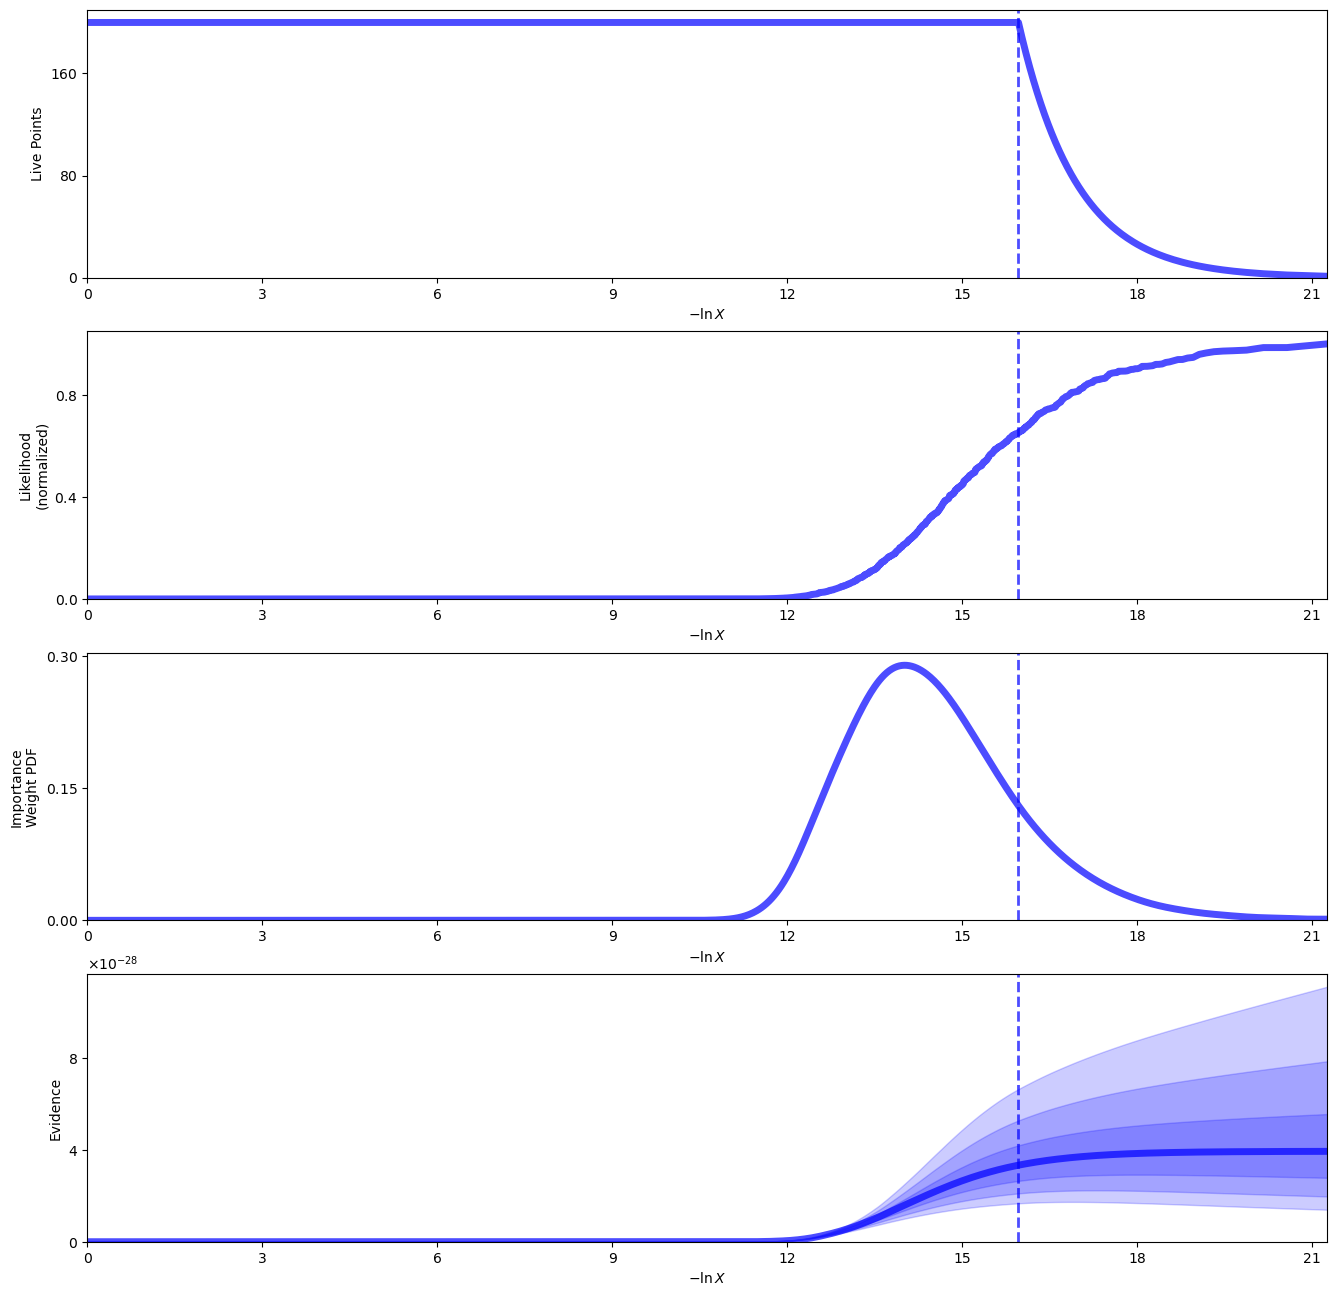

In [6]:
rfig, raxes = dyplot.runplot(sresults_burst)

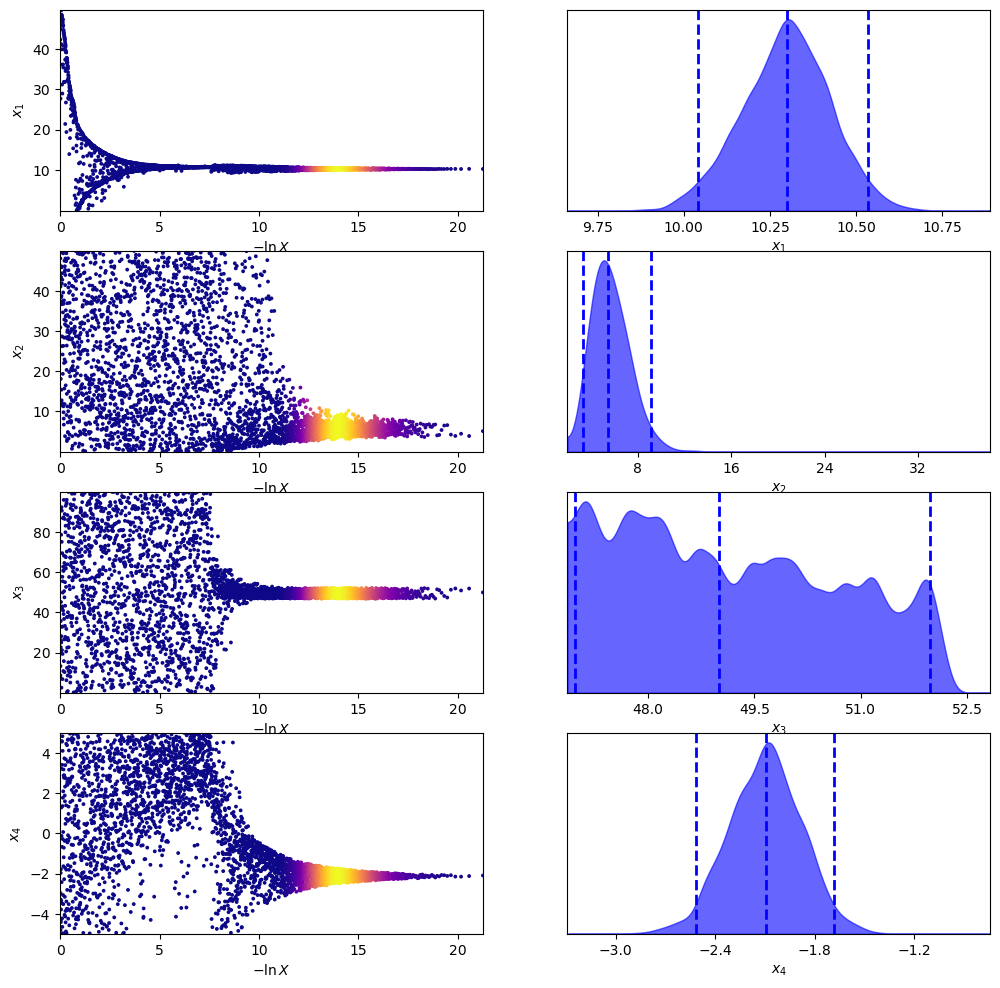

In [7]:
tfig, taxes = dyplot.traceplot(sresults_burst)

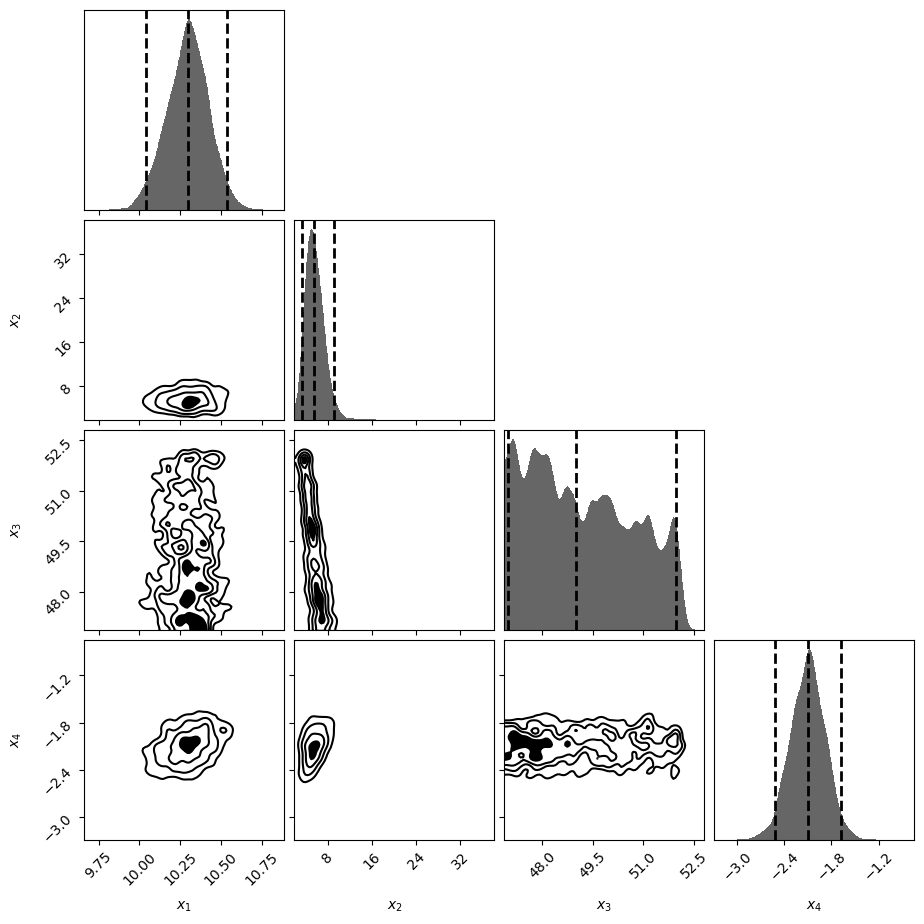

In [8]:
cfig, caxes = dyplot.cornerplot(sresults_burst)

Analysis for the Gaussian Model

In [ ]:
sampler_gauss = dynesty.NestedSampler(log_Likelihood, ptform, ndim, logl_args=[data,'gaussian'],ptform_args=['gaussian'],nlive=200)
sampler_gauss.run_nested()
sresults_gauss = sampler_gauss.results

rfig, raxes = dyplot.runplot(sresults_gauss)

In [ ]:
rfig, raxes = dyplot.traceplot(sresults_gauss)

In [ ]:
rfig, raxes = dyplot.cornerplot(sresults_gauss)

## Model Comparison

In [ ]:
# Extract sampling results.
samples_burst = sresults_burst.samples  # samples
weights_burst = np.exp(sresults_burst.logwt - sresults_burst.logz[-1])  # normalized weights

samples_gauss = sresults_gauss.samples  # samples
weights_gauss = np.exp(sresults_gauss.logwt - sresults_gauss.logz[-1])  # normalized weights


evidence_burst = sresults_burst.logz[-1] #evidence
print("Bayesian evidence for the burst model", np.exp(evidence_burst))

evidence_gauss = sresults_gauss.logz[-1] #evidence
print("Bayesian evidence for the gaussian model", np.exp(evidence_gauss))

# Compute 10%-90% quantiles.
quantiles_burst = [dyfunc.quantile(samps, [0.16, 0.84], weights=weights_burst)
             for samps in samples_burst.T]
print('68% parameter credible regions are:\n ' + str(quantiles_burst) + '\n')

# Compute 10%-90% quantiles.
quantiles_gauss = [dyfunc.quantile(samps, [0.16, 0.84], weights=weights_gauss)
             for samps in samples_gauss.T]
print('68% parameter credible regions are:\n ' + str(quantiles_gauss) + '\n')


# Compute weighted mean and covariance.
mean_burst, cov_burst = dyfunc.mean_and_cov(samples_burst, weights_burst)
print('Mean and covariance of parameters are: ' + str(mean_burst) + '\n' + str(cov_burst))

mean_gauss, cov_gauss = dyfunc.mean_and_cov(samples_gauss, weights_gauss)
print('Mean and covariance of parameters are: ' + str(mean_gauss) + '\n' + str(cov_gauss))

# Generate a new set of results with statistical+sampling uncertainties.
#results_sim = dyfunc.simulate_run(sresults)